# Milestone 3 — Iteracyjny trening modelu PM2.5 (horyzont 24 h)

Notatnik korzysta wyłącznie ze zmaterializowanej warstwy **Gold** (`data/gold/`, przygotowanej w `08_gold.ipynb`) poprzez kontraktowy odczyt `gold.load_gold()`. Funkcje treningu, metryk i diagnostyki znajdują się w `scripts/model_pm25.py`.

## 1. Iteracja 1 — Model bazowy (Baseline)

Model bazowy używa wyłącznie **8 surowych cech** (`temperature_2m`, `relative_humidity_2m`, `precipitation`, `surface_pressure`, `wind_speed_10m`, `godzina`, `dzien_tygodnia`, `miesiac`) oraz domyślnych hiperparametrów `HistGradientBoostingRegressor(random_state=42)` — bez cech inżynierskich z M2, bez lokalizacji stacji i bez historii `pm25_lag24/168`. Dzięki temu uzyskujemy czysty punkt startowy przed Iteracją 2.

Wynik zestawiamy z dwoma naiwnymi punktami odniesienia: **Dummy (średnia z `train`)** oraz **Persystencją 24 h (`pm25_lag24`, czyli „jutro tyle co dziś”)**.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts import model_pm25 as modeling

res1 = modeling.run_iteration1()
metrics1 = res1["metrics"]
diag1 = res1["diagnostics"]

baseline_row = metrics1.filter(pl.col("model").str.starts_with("Iteracja 1")).row(0, named=True)
pers_row = metrics1.filter(pl.col("model").str.starts_with("Persystencja")).row(0, named=True)
assert not np.isnan(res1["y_pred"]).any()
assert baseline_row["MAE"] < pers_row["MAE"] and baseline_row["R2"] > pers_row["R2"]

print("Cechy Iteracji 1:", modeling.BASELINE_FEATURES)
metrics1

Cechy Iteracji 1: ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'surface_pressure', 'wind_speed_10m', 'godzina', 'dzien_tygodnia', 'miesiac']


model,cechy,n_test,MAE,RMSE,R2
str,i64,i64,f64,f64,f64
"""Dummy (średnia z train)""",0,100282,8.253,11.969,-0.05
"""Persystencja 24 h (pm25_lag24)""",1,98626,6.838,11.619,0.0144
"""Iteracja 1 — Baseline (HGBR, 8…",8,100282,5.887,9.719,0.3076


### 1.1. Wstępna diagnoza błędów (dlaczego R² ≈ 0,31?)

Model bazowy wyraźnie bije naiwną persystencję 24 h ($R^2$: `0,308` vs `0,014`; `MAE`: `5,89` vs `6,84 µg/m³`), ale nadal wyjaśnia tylko ok. 31% wariancji. Poniższe przekroje na zbiorze testowym pokazują dokładnie, gdzie powstają błędy.

In [2]:
print("1) Błąd wg poziomu PM2.5 (bias = pred - prawda):")
display(diag1["by_pm25_bin"])

print("2) Błąd wg kwartału (sezonowość):")
display(diag1["by_quarter"])

print("3) Błąd wg typu stacji oraz 5 najgorszych / 5 najlepszych stacji (n >= 500):")
display(diag1["by_station_type"])
display(diag1["stations"].head(5))
display(diag1["stations"].tail(5).reverse())

1) Błąd wg poziomu PM2.5 (bias = pred - prawda):


przedzial_pm25,n,udzial_proc,srednie_pm25,srednia_pred,MAE,bias
enum,u32,f64,f64,f64,f64,f64
"""<15""",71978,71.78,8.12,11.59,4.36,3.46
"""15-35""",24430,24.36,21.13,16.71,6.74,-4.41
"""35-75""",3374,3.36,46.48,24.79,22.27,-21.69
""">=75""",500,0.5,105.74,32.77,73.15,-72.97


2) Błąd wg kwartału (sezonowość):


kwartal,n,srednie_pm25,srednia_pred,MAE
i8,u32,f64,f64,f64
1,24824,15.34,16.08,7.36
2,24938,11.74,11.06,4.72
3,25529,10.0,10.91,3.78
4,24991,15.28,15.56,7.75


3) Błąd wg typu stacji oraz 5 najgorszych / 5 najlepszych stacji (n >= 500):


typ_stacji,n,srednie_pm25,srednia_pred,MAE,bias
enum,u32,f64,f64,f64,f64
"""przemysłowa""",1714,14.1,14.25,6.29,0.16
"""komunikacyjna""",13688,15.06,13.67,6.1,-1.39
"""tło""",84880,12.73,13.32,5.84,0.59


kod_stacji,typ_stacji,n,srednie_pm25,srednia_pred,MAE
str,enum,u32,f64,f64,f64
"""SlZywieKoper""","""tło""",667,16.84,15.45,9.65
"""DsKlodzSzkol""","""tło""",1086,16.72,14.89,8.9
"""OpOpoleKoszy""","""tło""",1091,13.76,14.41,8.72
"""SlKatoPlebA4""","""komunikacyjna""",747,20.34,12.75,8.23
"""PdBorsukowiz""","""tło""",1039,6.15,13.87,8.07


kod_stacji,typ_stacji,n,srednie_pm25,srednia_pred,MAE
str,enum,u32,f64,f64,f64
"""ZpKolZolkiew""","""tło""",729,8.96,10.75,3.99
"""PkRzeszSloci""","""tło""",610,12.34,12.57,4.36
"""MzRadTochter""","""tło""",1074,14.4,13.32,4.36
"""PmSopBiPlowc""","""tło""",1044,10.62,11.38,4.39
"""ZpSzczPilsud""","""komunikacyjna""",1085,12.15,12.72,4.61


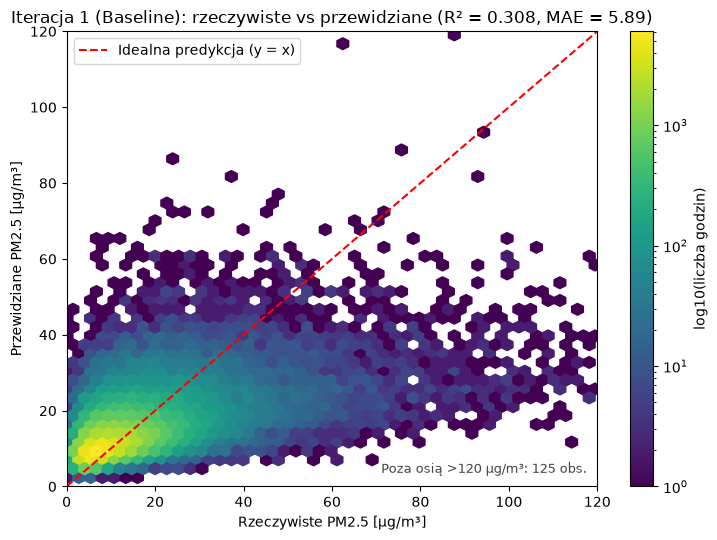

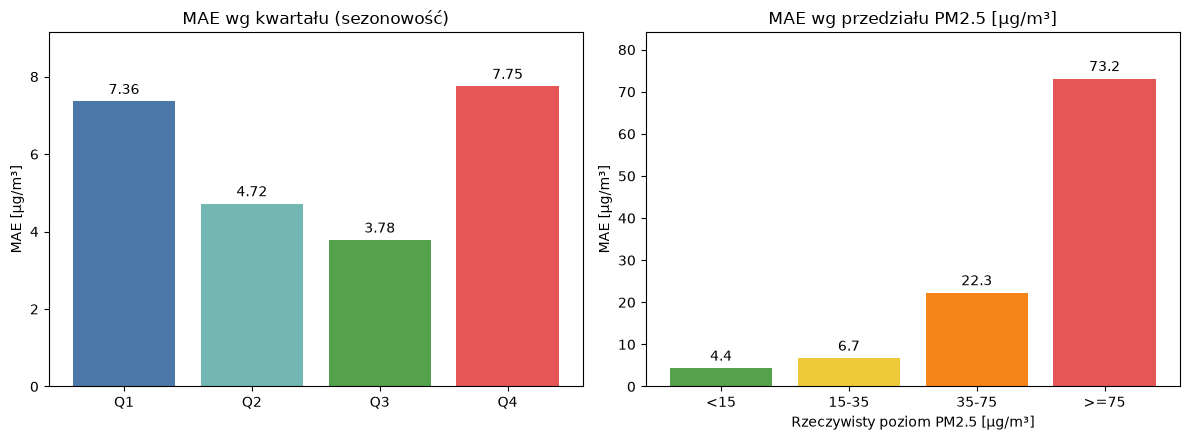

In [3]:
y_true = res1["y_test"]
y_pred = res1["y_pred"]
limit = 120.0
above = int((y_true > limit).sum())

# Wykres 1: Rzeczywiste vs Przewidziane (gęstość hexbin pokazuje spłaszczenie górnego ogona)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
mask = (y_true <= limit) & (y_pred <= limit)
hb = ax.hexbin(y_true[mask], y_pred[mask], gridsize=45, bins="log", cmap="viridis", mincnt=1)
ax.plot([0, limit], [0, limit], "r--", lw=1.5, label="Idealna predykcja (y = x)")
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_xlabel("Rzeczywiste PM2.5 [µg/m³]")
ax.set_ylabel("Przewidziane PM2.5 [µg/m³]")
ax.set_title(f"Iteracja 1 (Baseline): rzeczywiste vs przewidziane (R² = {baseline_row['R2']:.3f}, MAE = {baseline_row['MAE']:.2f})")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="log10(liczba godzin)")
ax.text(0.98, 0.03, f"Poza osią >{int(limit)} µg/m³: {above} obs.", transform=ax.transAxes, ha="right", fontsize=9, color="#444")
fig.tight_layout()
plt.show()

# Wykres 2: MAE wg kwartału oraz wg przedziału stężeń PM2.5
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

q_df = diag1["by_quarter"]
q_labels = [f"Q{q}" for q in q_df["kwartal"].to_list()]
q_mae = q_df["MAE"].to_list()
bars1 = ax1.bar(q_labels, q_mae, color=["#4C78A8", "#72B7B2", "#54A24B", "#E45756"])
ax1.bar_label(bars1, fmt="%.2f", padding=3)
ax1.set_title("MAE wg kwartału (sezonowość)")
ax1.set_ylabel("MAE [µg/m³]")
ax1.set_ylim(0, max(q_mae) * 1.18)

b_df = diag1["by_pm25_bin"]
b_labels = b_df["przedzial_pm25"].to_list()
b_mae = b_df["MAE"].to_list()
bars2 = ax2.bar(b_labels, b_mae, color=["#54A24B", "#EECA3B", "#F58518", "#E45756"])
ax2.bar_label(bars2, fmt="%.1f", padding=3)
ax2.set_title("MAE wg przedziału PM2.5 [µg/m³]")
ax2.set_xlabel("Rzeczywisty poziom PM2.5 [µg/m³]")
ax2.set_ylabel("MAE [µg/m³]")
ax2.set_ylim(0, max(b_mae) * 1.15)

fig.tight_layout()
plt.show()

### Wnioski z diagnozy (dlaczego R² ≈ 0,31 i co zmienimy w Iteracji 2)

1. **Brak pamięci epizodu smogowego (`pm25_lag24`, `pm25_lag168`)**: wykres *rzeczywiste vs przewidziane* ma wyraźny „sufit” predykcji w okolicach 35–45 µg/m³. Dla silnego smogu `>= 75 µg/m³` średnia prawda to ponad `105 µg/m³`, a model przewiduje ok. `33 µg/m³` (`MAE ≈ 73 µg/m³`), co przez kwadratowanie błędów drastycznie obniża $R^2$ i zawyża `RMSE` (`9,72`).
2. **Brak kontekstu przestrzennego i typu stacji**: wszystkie 127 stacji wpada do jednego worka — największe błędy występują w kotlinach i obszarach o silnej niskiej emisji (np. Żywiec, Kłodzko, Opole: `MAE ~9 µg/m³`), a najmniejsze nad morzem (Kołobrzeg: `MAE ~4 µg/m³`). Stacje komunikacyjne są systematycznie niedoszacowane (ujemny bias).
3. **Sezon grzewczy i brak pochodnych cech pogody**: zimą (`Q1`, `Q4`) `MAE` przekracza `7,3–7,8 µg/m³` (2× więcej niż w `Q3`: `3,78`), ponieważ surowa chwilowa pogoda nie zawiera `stopniodni_grzania`, wektorowego kierunku wiatru (`wiatr_u/v`), skumulowanego wymywania opadem (`opad_suma6h/24h`), dynamiki frontów (`cisnienie_zmiana3h`, `temperatura_zmiana24h`) ani kalendarza świąt.

**Plan na Iterację 2 (2 z 3 modyfikacji):**
1. **Zaawansowana inżynieria cech**: włączenie pozostałych 21 cech z warstwy Gold (historia 24 h / 168 h, cechy pochodne pogody i ogrzewania, cykliczny kalendarz, charakterystyka i położenie stacji).
2. **Dostrojenie hiperparametrów**: optymalizacja parametrów `HistGradientBoostingRegressor` z walidacją wyłącznie wewnątrz `train`.